# Student Outcome Classification and Academic Profile Analysis

**Команда:** Ансар Келес, Мухамеджан Сагым, Бекназар Сарсенбек.

Реальный датасет UCI 697. Три класса: Dropout, Enrolled, Graduate. Исследуем, как результаты семестров меняют качество исторической классификации. Код и черновики подготовлены с помощью Codex; фактический технический вклад студентов фиксируется отдельно в `docs/contributions.csv`.

## 1. Окружение и порядок запуска

Запускайте все ячейки последовательно в ядре **Python (Students Dropout)**. При отсутствии результатов модуль выполнит весь объявленный эксперимент. При наличии результатов проверяются хеши и используются зафиксированные артефакты. Полное повторение того же плана доступно через `scripts/run_project.py --reproduce`; повторно используемый test не становится новой независимой выборкой.

In [1]:
from pathlib import Path
import sys, json, random
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'project_config.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'project_config.json').exists(), 'Откройте notebook из папки проекта'
sys.path.insert(0, str(ROOT))
random.seed(42)
np.random.seed(42)
from src.data import load_data, engineer_features, feature_profiles, fixed_split
from src.workflow import run_experiments
environment = json.loads((ROOT / 'artifacts/environment.json').read_text())
print('Python:', sys.version.split()[0])
display(pd.Series({k: v for k, v in environment['packages'].items() if k in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'seaborn', 'nbformat', 'nbclient', 'ipykernel']}, name='version'))

Python: 3.14.8


ipykernel        7.4.0
matplotlib      3.11.2
nbclient        0.11.0
nbformat        5.11.1
numpy            2.5.5
pandas           3.1.1
scikit-learn     1.9.1
scipy           1.18.1
seaborn         0.13.2
Name: version, dtype: str

Версии полного окружения находятся в `requirements.lock.txt`. Все модели используют один источник и фиксированные seed. Последующие ячейки не выбирают настройки по test.

## 2. Источник, очистка и feature engineering

Исходный CSV сохраняется без изменения байтов и проверяется по SHA-256. Удаляется лишняя табуляция в заголовке; неизвестные значения образования/профессий родителей явно кодируются категорией Unknown. Нули не удаляются автоматически. Коды специальностей, гражданства и профессий являются категориями. Для каждого семестра добавлены доля сданных дисциплин, число оцениваний на дисциплину, доля дисциплин без оценивания и индикатор нулевой учебной нагрузки. При нулевом знаменателе ставка равна нулю, а отдельный индикатор сохраняет смысл случая.

In [2]:
raw_cleaned = load_data()
frame = engineer_features(raw_cleaned)
profiles = feature_profiles(frame)
audit = json.loads((ROOT / 'artifacts/data_audit.json').read_text())
print('Строк:', len(frame), '| Исходных признаков:', raw_cleaned.shape[1] - 1)
display(pd.Series(audit['encoded_unknown_counts'], name='coded_unknown_count'))
display(pd.read_csv(ROOT / 'artifacts/tables/cleaning_log.csv'))
display(pd.DataFrame([{'profile': name, 'features_after_engineering': len(columns)} for name, columns in profiles.items()]))

Строк: 4424 | Исходных признаков: 36


Mother's qualification:34    130
Father's qualification:34    112
Mother's occupation:99        17
Father's occupation:99        19
Name: coded_unknown_count, dtype: int64

,check,observed,action
0,source shape,"4424 rows, 37 columns",preserve every source row and target
1,empty cells,0,none present; no source imputation
2,full duplicates,0,none present; no rows removed
3,header whitespace,1,strip header whitespace in modelling memory; s...
4,nominal codes,9,cast to categorical strings; train-fitted one-...
5,binary codes,6,validate each observed value is 0 or 1
6,financial timestamps,Debtor; Tuition fees up to date,exclude from every core feature profile
7,target integrity,"{'Graduate': 2209, 'Dropout': 1421, 'Enrolled'...",preserve all three outcome classes; no imputat...
8,feature engineering,8,fixed row-wise ratios and zero-enrollment flag...
9,outliers and zero grades,valid source extremes retained,no target-driven trimming or automatic deletio...


,profile,features_after_engineering
0,non_semester,22
1,plus_semester_1,32
2,plus_semester_2,42


Target не заполняется и не используется в признаках. Debtor и Tuition fees up to date исключены из всех основных профилей из-за неопределённой даты наблюдения. При сравнении профилей не утверждается, что все остальные изменяемые статусы точно доступны при поступлении.

## 3. Разбиение и объявленный эксперимент

Один stratified split 70/15/15, seed 42. Все кандидаты обучаются только на train; пять CV-fold находятся внутри train. One-hot encoder, median imputer и StandardScaler входят в Pipeline, поэтому при CV они переобучаются внутри каждого training fold. Настройки и лучший основной алгоритм выбираются без test.

In [3]:
splits, split_manifest = fixed_split(frame)
summary = run_experiments(reuse=True)
display(pd.read_csv(ROOT / 'artifacts/tables/split_counts.csv', index_col=0))
print('Хеш плана:', summary['plan_sha256'])

Loaded verified frozen results; no models retrained and no new test selection.


,Dropout,Enrolled,Graduate
split,,,
train,994,556,1546
validation,213,119,332
test,214,119,331


Хеш плана: a0ca5ae70dce9f23dba8c427de41ef72fa34c53689340966d810f77940b98fa5


План поиска записан до обучения в `artifacts/experiment_plan.json`. Настройки и выбранная модель сохранены в `artifacts/frozen_models.json` до расчёта test-метрик. Случайное разбиение оценивает историческую выборку и не имитирует новые годы поступления.

## 4. EDA: только тренировочные наблюдения

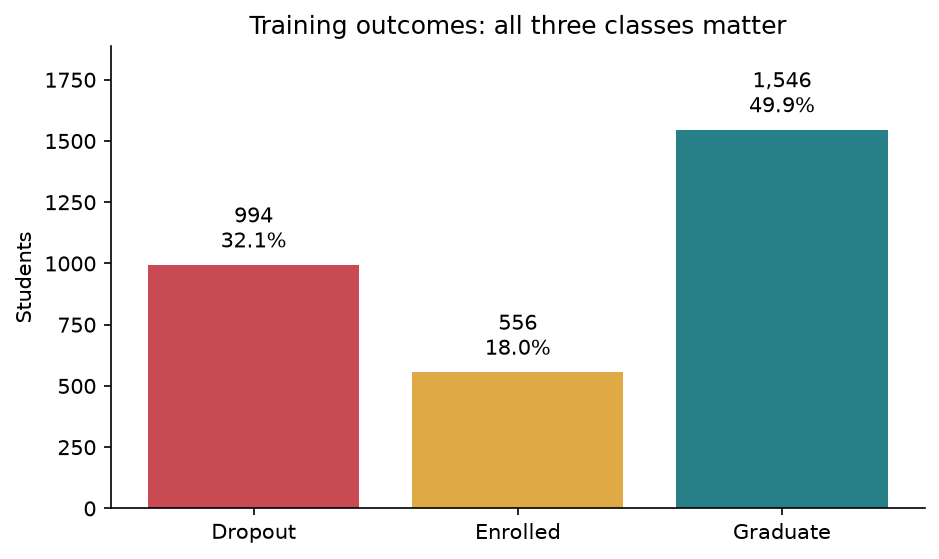

In [4]:
display(Image(filename=str(ROOT / 'artifacts/figures/eda_01_class_balance.png')))

Распределение исходов неравномерное. Macro F1 учитывает все три класса; одна accuracy может скрывать слабый результат на Enrolled.

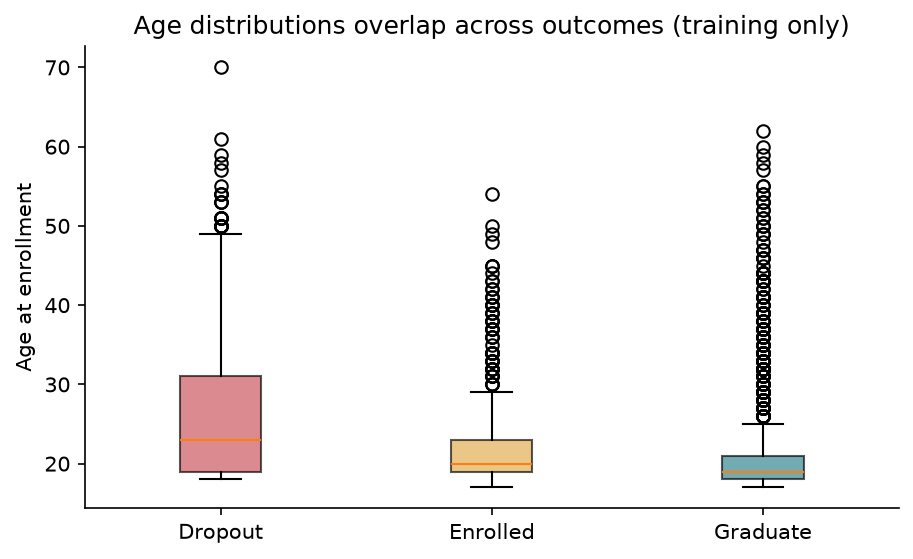

In [5]:
display(Image(filename=str(ROOT / 'artifacts/figures/eda_02_age.png')))

Возраст в train: 17–70 лет. Распределения перекрываются; возраст не определяет исход отдельного студента.

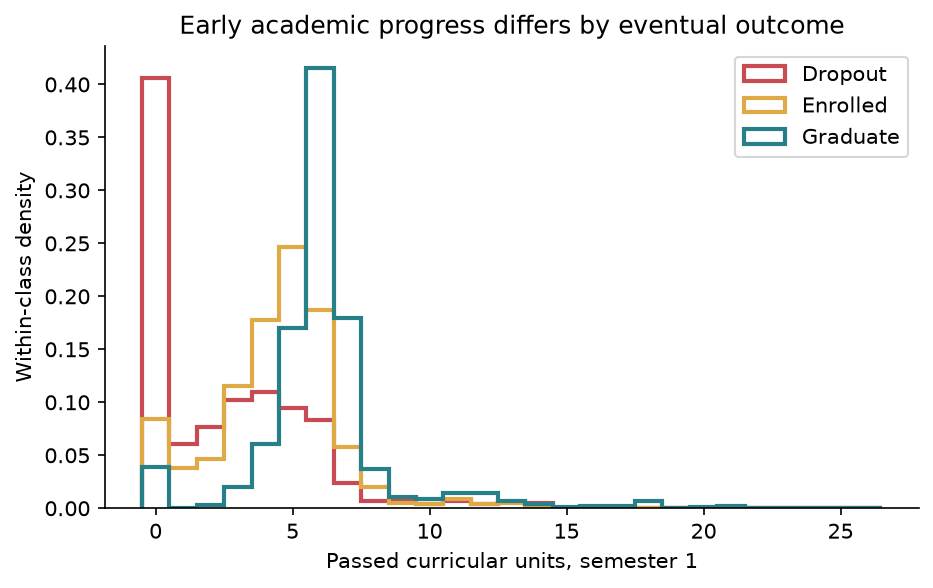

In [6]:
display(Image(filename=str(ROOT / 'artifacts/figures/eda_03_passed_units.png')))

Среднее число сданных дисциплин первого семестра в train: Dropout — 2.58, Enrolled — 4.40, Graduate — 6.17. Это ассоциация с будущим статусом, не доказательство причины.

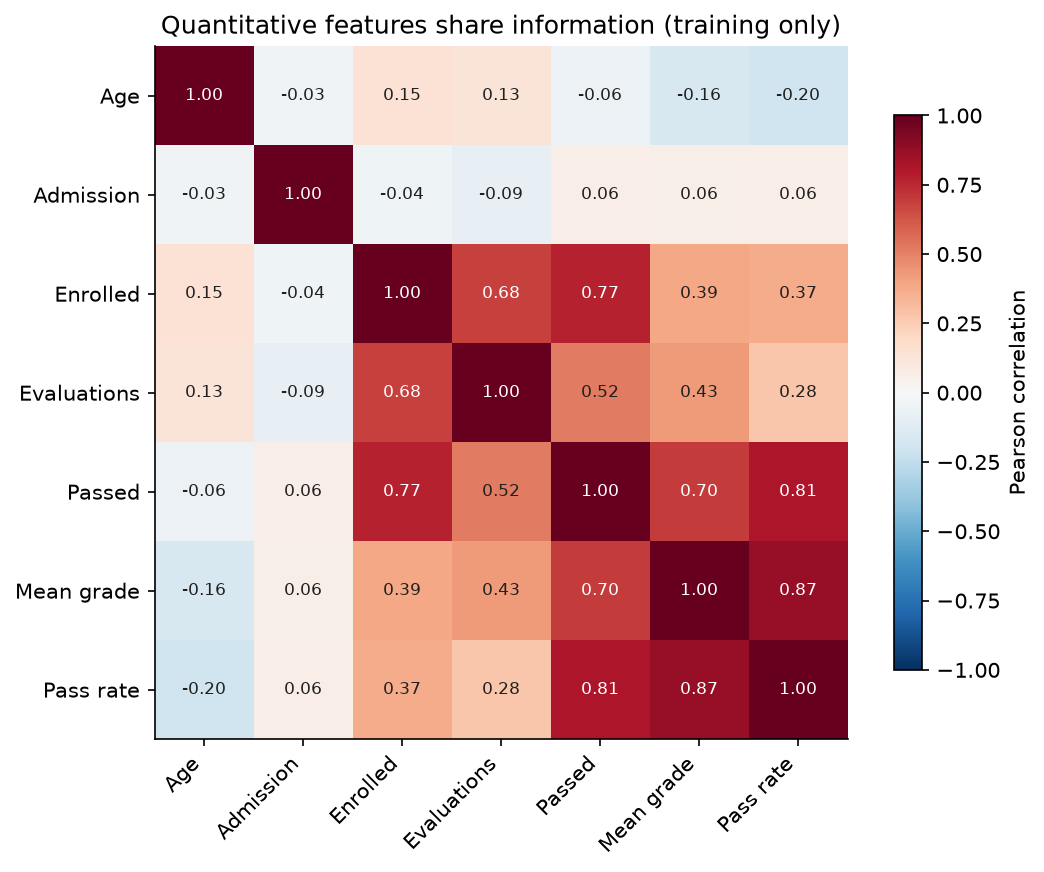

In [7]:
display(Image(filename=str(ROOT / 'artifacts/figures/eda_04_correlations.png')))

Корреляция количества сданных дисциплин со средней оценкой в train: 0.702. Коррелированные академические показатели частично дублируют информацию; PCA ниже исследует эту структуру.

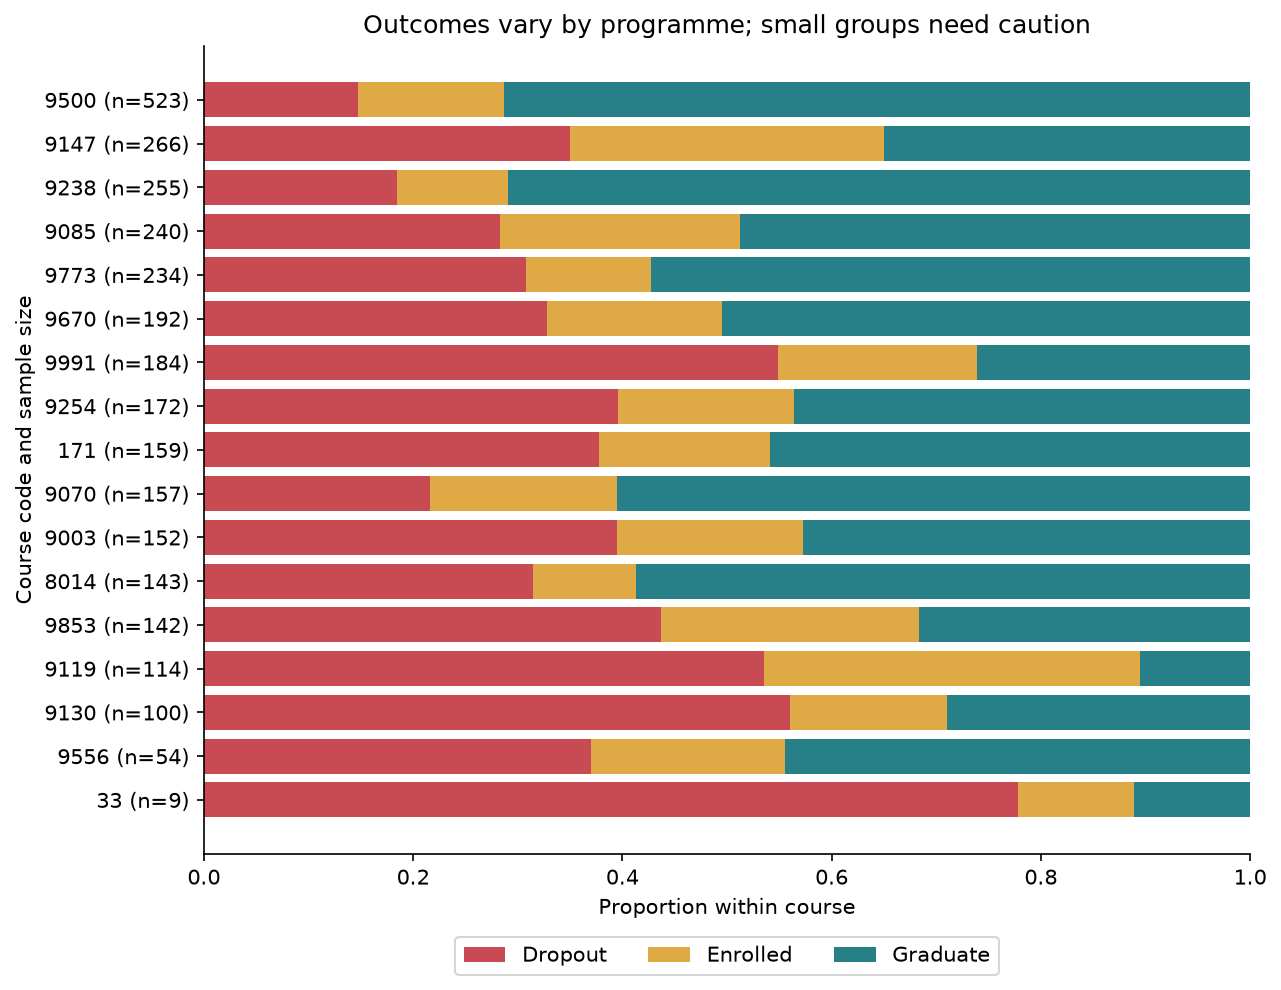

In [8]:
display(Image(filename=str(ROOT / 'artifacts/figures/eda_05_courses.png')))

Доли исходов различаются между программами. Сопоставляйте их с числом наблюдений; различия могут отражать состав студентов и особенности программы.

## 5. Baseline, лекционные алгоритмы и hyperparameter tuning

Baseline всегда предсказывает наиболее частый класс train. Logistic Regression использует C ∈ {0.1, 1, 10} и обычные/сбалансированные веса. Decision Tree проверяет глубины {3, 5, 8, без ограничения}, min_samples_leaf ∈ {5, 15} и веса классов. KNN проверяет k ∈ {5, 15, 31} и uniform/distance weights. Это ограниченный заранее объявленный поиск сложности, регуляризации и чувствительности к дисбалансу. Для каждого алгоритма лучший кандидат выбирается по среднему training-CV Macro F1. Масштабирование нужно LR/KNN/ANN; дерево обучается без него. Соответствие алгоритмов программе лекций проверяет команда.

In [9]:
for filename in ['cv_logistic_main.csv', 'cv_tree_main.csv', 'cv_knn_main.csv']:
    cv_table = pd.read_csv(ROOT / 'artifacts/tables' / filename)
    print(filename)
    display(cv_table[['params', 'mean_test_score', 'std_test_score', 'mean_train_score', 'rank_test_score']].sort_values('rank_test_score').head(5))

cv_logistic_main.csv


,params,mean_test_score,std_test_score,mean_train_score,rank_test_score
1,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.648264,0.005153,0.685429,1
3,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.642429,0.019905,0.702006,2
5,"{'model__C': 10.0, 'model__class_weight': 'bal...",0.636280,0.024061,0.704802,3
2,"{'model__C': 1.0, 'model__class_weight': None}",0.634356,0.012230,0.692144,4
4,"{'model__C': 10.0, 'model__class_weight': None}",0.628753,0.015557,0.703731,5


cv_tree_main.csv


,params,mean_test_score,std_test_score,mean_train_score,rank_test_score
8,"{'model__class_weight': 'balanced', 'model__ma...",0.611242,0.022156,0.628892,1
9,"{'model__class_weight': 'balanced', 'model__ma...",0.611242,0.022156,0.628892,1
11,"{'model__class_weight': 'balanced', 'model__ma...",0.610263,0.022743,0.658245,3
13,"{'model__class_weight': 'balanced', 'model__ma...",0.608959,0.016278,0.696377,4
10,"{'model__class_weight': 'balanced', 'model__ma...",0.607187,0.024345,0.662215,5


cv_knn_main.csv


,params,mean_test_score,std_test_score,mean_train_score,rank_test_score
2,"{'model__n_neighbors': 15, 'model__weights': '...",0.561214,0.018384,0.616313,1
1,"{'model__n_neighbors': 5, 'model__weights': 'd...",0.559918,0.015545,1.000000,2
0,"{'model__n_neighbors': 5, 'model__weights': 'u...",0.559522,0.021566,0.695926,3
3,"{'model__n_neighbors': 15, 'model__weights': '...",0.559262,0.014219,1.000000,4
4,"{'model__n_neighbors': 31, 'model__weights': '...",0.539171,0.020216,0.576138,5


Здесь mean_test_score означает отложенную часть CV-fold внутри train, а не финальный test. Среднее и разброс CV помогают оценить устойчивость результатов. Если train-score существенно выше CV-score, это признак возможного переобучения.

## 6. Feedforward ANN

Выбрана архитектура **229 → 32 → 3**, 7,459 параметров. ReLU в скрытых слоях и softmax для трёх классов; cross-entropy, L2, Adam (learning rate 0.001, beta1=0.9, beta2=0.999, epsilon=1e-8), batch 64. Четыре кандидата сравнивают ширину, L2 и взвешивание классов. Максимум 200 эпох; patience 25 по validation Macro F1. Восстанавливается лучший checkpoint, при точном равенстве F1 — с меньшей validation cross-entropy. На графиках показаны невзвешенные loss, даже если оптимизация кандидата использовала веса.

,name,hidden,alpha,balanced,best_epoch,stopped_epoch,validation_macro_f1,validation_log_loss,fit_seconds
0,ann_32,[32],0.001,False,16,41,0.624378,0.694655,0.925
1,ann_64_32,"[64, 32]",0.001,False,21,46,0.656884,0.872440,1.181
2,ann_32_weighted,[32],0.010,True,9,34,0.662481,0.731329,0.729
3,ann_64_32_weighted,"[64, 32]",0.010,True,8,33,0.661778,0.752905,0.897


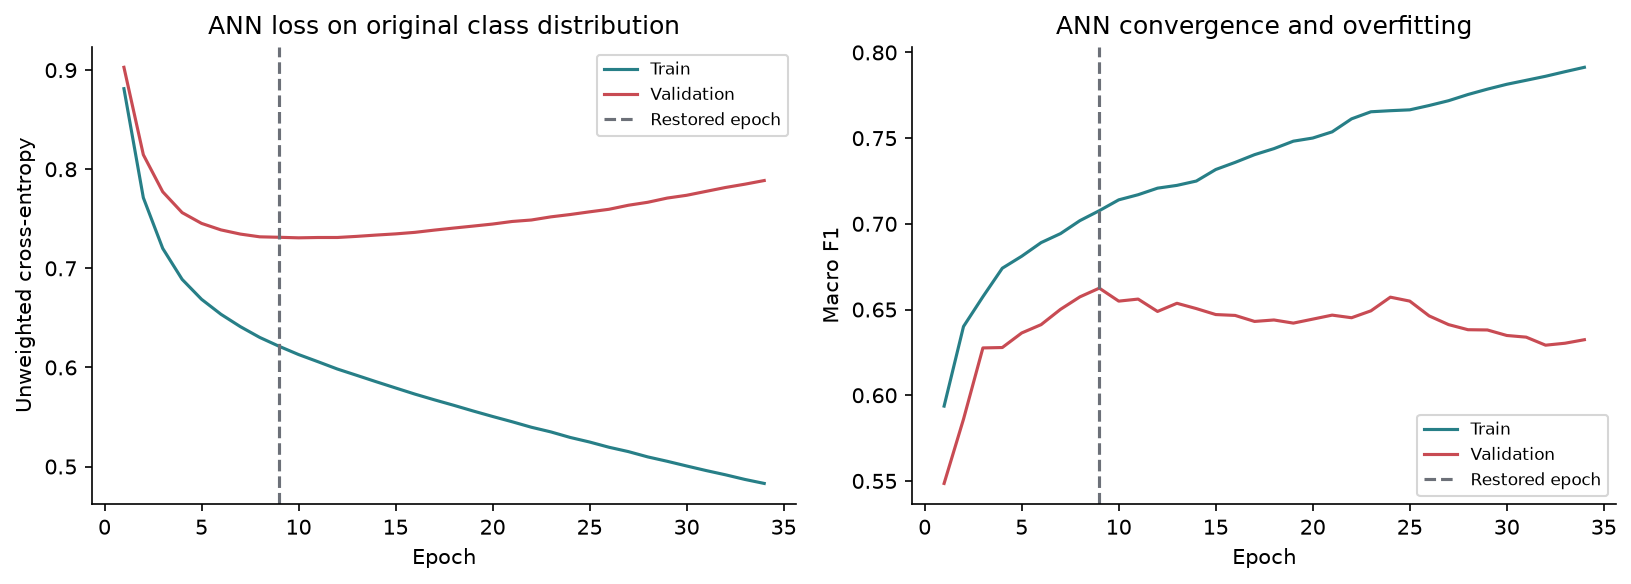

Восстановлена эпоха: 9 | остановка: 34


In [10]:
display(pd.read_csv(ROOT / 'artifacts/tables/ann_candidates.csv'))
display(Image(filename=str(ROOT / 'artifacts/figures/ann_training_history.png')))
print('Восстановлена эпоха:', summary['ann']['best_epoch'], '| остановка:', summary['ann']['stopped_epoch'])

Снижение train loss при ухудшении validation loss указывает на переобучение. Кривые нужно интерпретировать вместе с выбранной эпохой и Macro F1. ANN использует те же train/validation/test и признаки, что основные классические модели; число кандидатов и способ настройки различаются и указаны явно.

У выбранной ANN на эпохе 9 train Macro F1=0.708, validation Macro F1=0.662. К последней эпохе train Macro F1 вырастает до 0.791, а validation становится 0.632. Поэтому восстановлен ранний checkpoint; поздние эпохи не улучшили качество на validation.

## 7. K-Means и интерпретация групп

Используются пять количественных показателей первого семестра: enrolled, evaluations, approved, grade, without evaluations. Перезачёты исключены, поскольку описывают признание предыдущего обучения, а не только текущую активность. StandardScaler обучается на train. Проверяются k=2..6, n_init=20 и seed 42/43/44. Основной критерий — silhouette при минимальном размере группы 5%; ARI показывает устойчивость к инициализации. Target добавляется для описания только после выбора k.

,k,inertia,silhouette,minimum_cluster_fraction,mean_seed_ari
0,2,9952.8019,0.5726,0.1657,1.0000
1,3,6992.2981,0.6002,0.0591,1.0000
2,4,5251.8197,0.6197,0.0310,0.9993
3,5,4531.4988,0.3821,0.0310,0.9979
4,6,3925.6178,0.3959,0.0310,0.9979


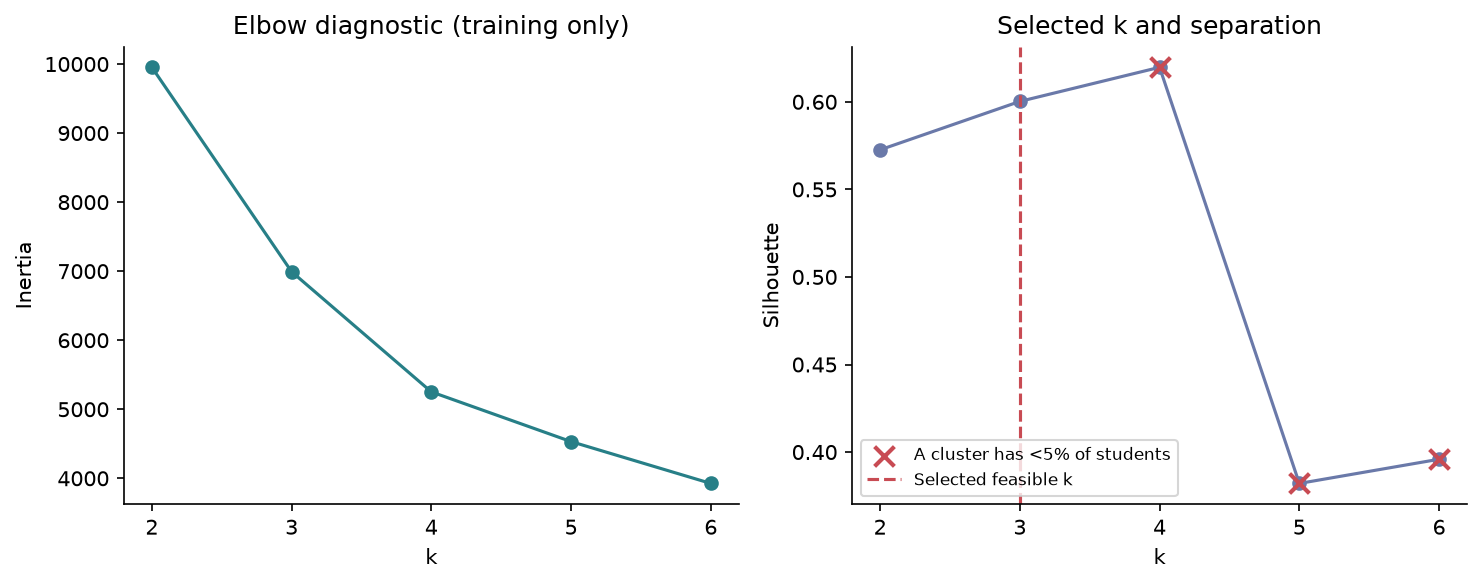

,cluster,n,mean_Curricular units 1st sem (enrolled),mean_Curricular units 1st sem (evaluations),mean_Curricular units 1st sem (approved),mean_Curricular units 1st sem (grade),mean_Curricular units 1st sem (without evaluations),share_Dropout,share_Enrolled,share_Graduate
0,0,2401,6.165,8.546,5.166,12.732,0.093,0.225,0.202,0.573
1,1,512,4.055,3.674,0.004,0.021,0.232,0.791,0.092,0.117
2,2,183,13.437,17.049,11.689,12.589,0.503,0.268,0.126,0.607


In [11]:
display(pd.read_csv(ROOT / 'artifacts/tables/cluster_selection.csv').round(4))
display(Image(filename=str(ROOT / 'artifacts/figures/cluster_selection.png')))
display(pd.read_csv(ROOT / 'artifacts/tables/cluster_profiles.csv').round(3))

Выбрано **k=3**, silhouette=0.600, mean seed ARI=1.000. Размеры групп и их академические профили приведены выше. Инициализационная устойчивость не доказывает существование естественных типов студентов. Кластеризация дополняет классификацию.

**Кластер 0: обычная учебная нагрузка с выраженным академическим прогрессом.** n=2401; среднее число зарегистрированных дисциплин 6.16, успешно сданных 5.17, средняя оценка 12.73. Доля Dropout=22.5%. Это описание исторических записей, а не диагноз или доказанная причина исхода.

**Кластер 1: почти отсутствуют успешно сданные дисциплины.** n=512; среднее число зарегистрированных дисциплин 4.05, успешно сданных 0.00, средняя оценка 0.02. Доля Dropout=79.1%. Это описание исторических записей, а не диагноз или доказанная причина исхода.

**Кластер 2: повышенная зарегистрированная учебная нагрузка.** n=183; среднее число зарегистрированных дисциплин 13.44, успешно сданных 11.69, средняя оценка 12.59. Доля Dropout=26.8%. Это описание исторических записей, а не диагноз или доказанная причина исхода.

Максимальная silhouette сама по себе не определяет выбор k: вариант, создающий группу меньше 5% train, исключается по заранее объявленному ограничению. Высокая нагрузка может отражать устройство программы; больше сданных дисциплин не обязательно означает более высокую среднюю оценку.

## 8. PCA

PCA обучается на тех же стандартизованных тренировочных показателях. Это исследовательская проекция; основные supervised-модели не заменяют признаки на PCA-компоненты.

,component,explained_variance_ratio,cumulative_variance
0,1,0.5544,0.5544
1,2,0.2235,0.7780
2,3,0.1198,0.8978
3,4,0.0814,0.9792
4,5,0.0208,1.0000


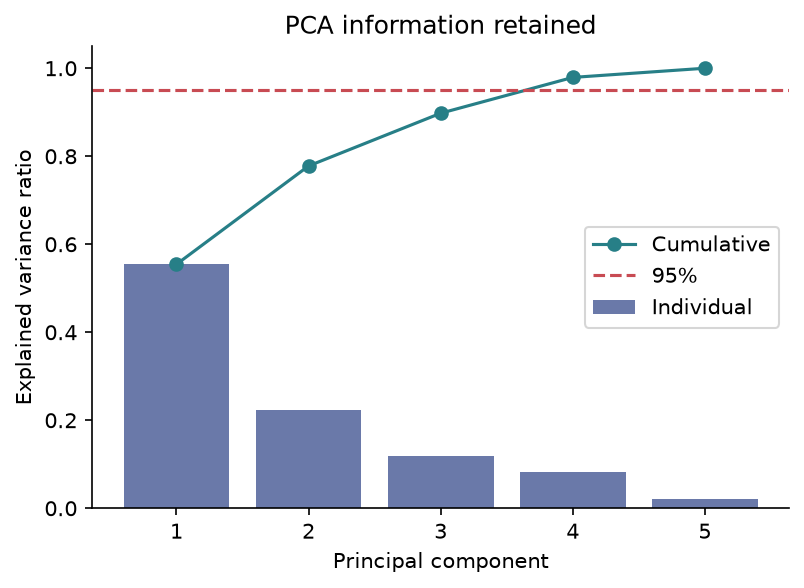

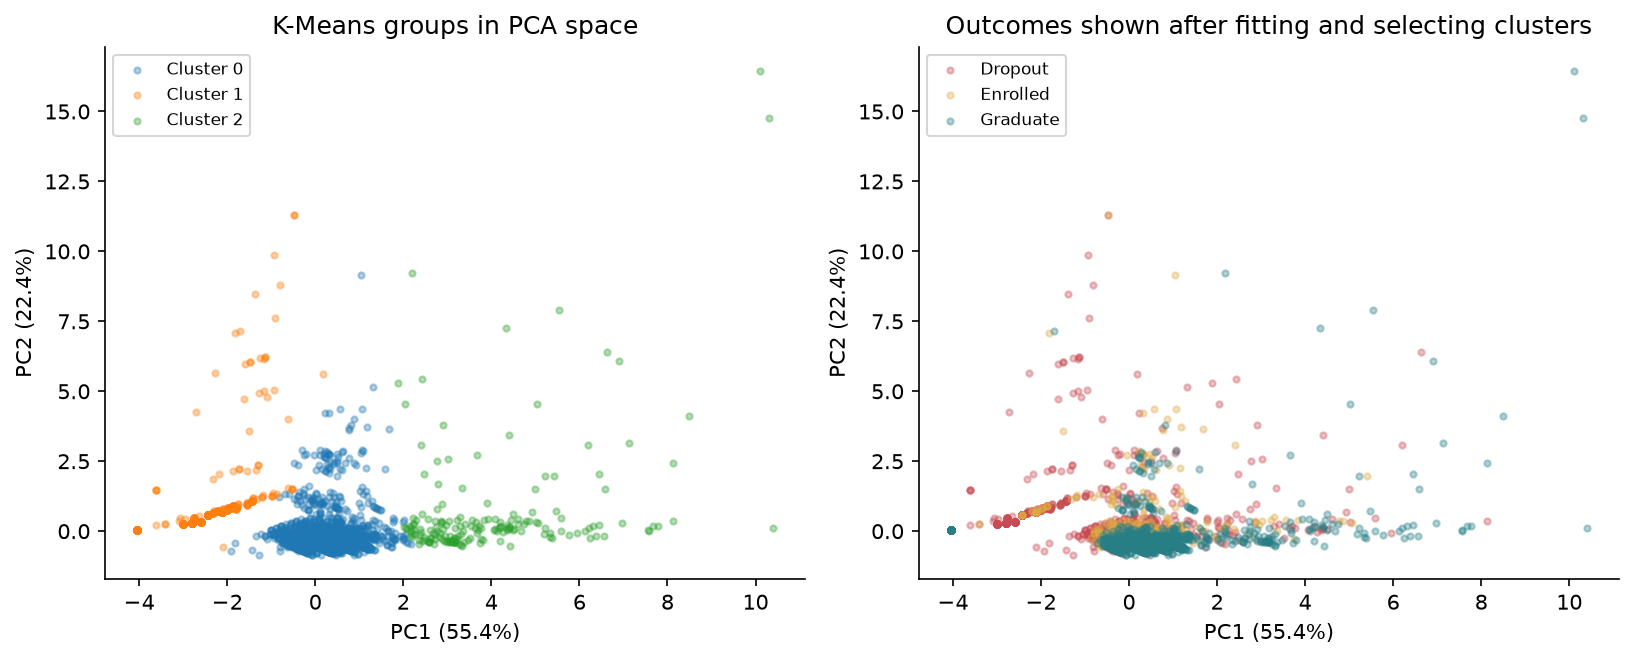

,PC1,PC2,PC3,PC4,PC5
Curricular units 1st sem (enrolled),0.523,0.095,-0.493,-0.350,-0.593
Curricular units 1st sem (evaluations),0.479,0.280,-0.267,0.748,0.247
Curricular units 1st sem (approved),0.543,-0.205,0.066,-0.466,0.665
Curricular units 1st sem (grade),0.443,-0.326,0.711,0.218,-0.381
Curricular units 1st sem (without evaluations),0.082,0.874,0.420,-0.230,-0.001


In [12]:
display(pd.read_csv(ROOT / 'artifacts/tables/pca_variance.csv').round(4))
display(Image(filename=str(ROOT / 'artifacts/figures/pca_variance.png')))
display(Image(filename=str(ROOT / 'artifacts/figures/pca_clusters.png')))
display(pd.read_csv(ROOT / 'artifacts/tables/pca_loadings.csv', index_col=0).round(3))

Первые две компоненты сохраняют **77.80%** дисперсии. Для сохранения минимум 95% нужны **4** компоненты. Двумерная картинка теряет оставшуюся информацию; перекрытие групп и классов нельзя интерпретировать как отсутствие структуры во всех исходных измерениях.

## 9. Единое итоговое сравнение

Выбранная по validation модель: **ANN**. После заморозки настроек все модели оценены на общем test. Train+validation refit не выполнялся. Основная метрика — Macro F1; отдельно анализируются recall/precision Dropout, balanced accuracy и accuracy.

,model,cv_macro_f1,validation_macro_f1,validation_accuracy,validation_balanced_accuracy,validation_dropout_precision,validation_dropout_recall,test_macro_f1,test_accuracy,test_balanced_accuracy,test_dropout_precision,test_dropout_recall,selected_on_validation,training_rows,encoded_features
0,Dummy,NaN,0.2222,0.5000,0.3333,0.0000,0.0000,0.2218,0.4985,0.3333,0.0000,0.0000,False,3096,229
1,Logistic Regression,0.6483,0.6535,0.6928,0.6616,0.7849,0.6338,0.6899,0.7304,0.7002,0.8021,0.7009,False,3096,229
2,Decision Tree,0.6112,0.5893,0.6235,0.5961,0.7640,0.5775,0.6356,0.6657,0.6496,0.7865,0.6542,False,3096,229
3,KNN,0.5612,0.5416,0.6642,0.5420,0.7160,0.5446,0.5871,0.7033,0.5846,0.7771,0.6355,False,3096,229
4,ANN,NaN,0.6625,0.7048,0.6683,0.7680,0.6526,0.6785,0.7289,0.6822,0.7750,0.7243,True,3096,229


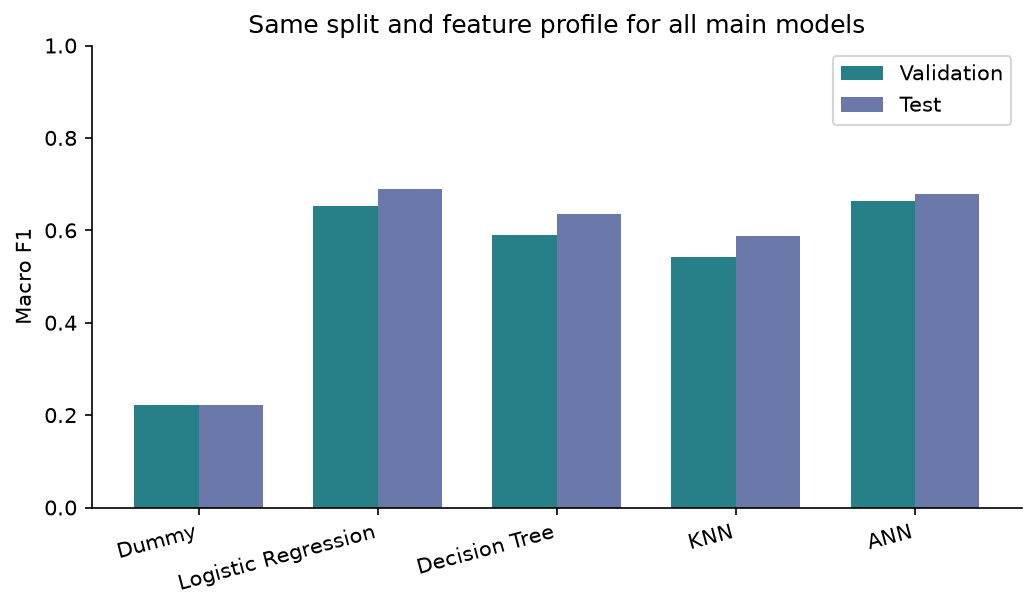

,model,class,precision,recall,f1,support
0,Dummy,Dropout,0.0000,0.0000,0.0000,214
1,Dummy,Enrolled,0.0000,0.0000,0.0000,119
2,Dummy,Graduate,0.4985,1.0000,0.6653,331
3,Logistic Regression,Dropout,0.8021,0.7009,0.7481,214
4,Logistic Regression,Enrolled,0.4162,0.6050,0.4932,119
5,Logistic Regression,Graduate,0.8651,0.7946,0.8283,331
6,Decision Tree,Dropout,0.7865,0.6542,0.7143,214
7,Decision Tree,Enrolled,0.3272,0.5966,0.4226,119
8,Decision Tree,Graduate,0.8587,0.6979,0.7700,331
9,KNN,Dropout,0.7771,0.6355,0.6992,214


In [13]:
comparison = pd.read_csv(ROOT / 'artifacts/tables/final_comparison.csv')
display(comparison.round(4))
display(Image(filename=str(ROOT / 'artifacts/figures/model_comparison.png')))
display(pd.read_csv(ROOT / 'artifacts/tables/test_class_metrics.csv').round(4))

Возможное отличие ранжирования на test не меняет модель, выбранную по validation. Значения test не используются для изменения параметров или признаков.

## 10. Сравнение групп признаков

Для трёх профилей применяется Logistic Regression с одинаковой сеткой и training-CV. Добавление семестровых результатов проверяет ценность дополнительной информации. Это историческая ablation; доступность всех статусов в конкретную дату не установлена.

,profile,input_features,cv_macro_f1,validation_macro_f1,validation_accuracy,validation_balanced_accuracy,validation_dropout_precision,validation_dropout_recall,test_macro_f1,test_accuracy,test_balanced_accuracy,test_dropout_precision,test_dropout_recall
0,non_semester,22,0.5250,0.5134,0.5422,0.5261,0.5606,0.5211,0.5683,0.5949,0.5849,0.6400,0.5981
1,plus_semester_1,32,0.6483,0.6535,0.6928,0.6616,0.7849,0.6338,0.6899,0.7304,0.7002,0.8021,0.7009
2,plus_semester_2,42,0.6898,0.6659,0.7063,0.6759,0.7886,0.6479,0.7255,0.7636,0.7375,0.8272,0.7383


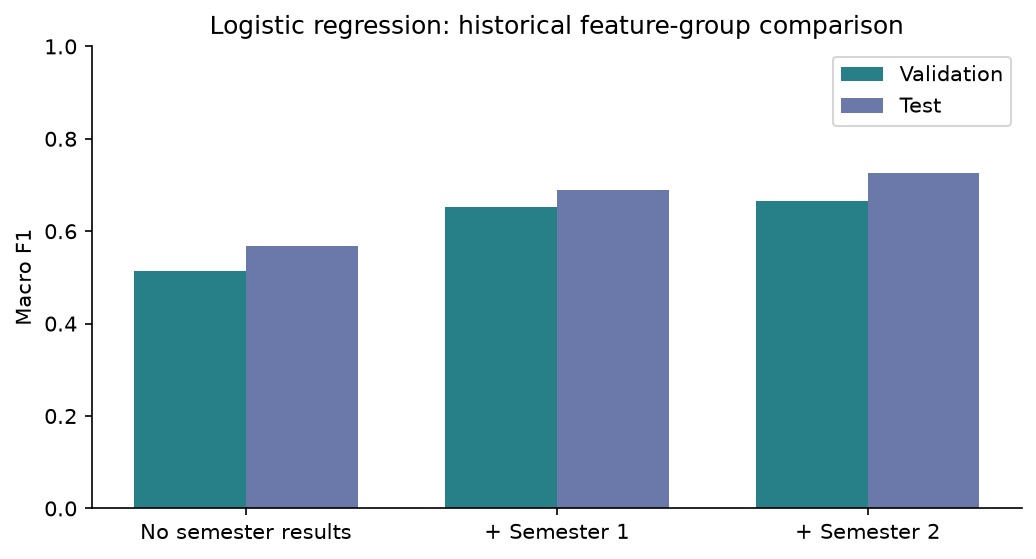

In [14]:
display(pd.read_csv(ROOT / 'artifacts/tables/feature_ablation.csv').round(4))
display(Image(filename=str(ROOT / 'artifacts/figures/feature_ablation.png')))

## 11. Ошибки, интерпретация и ограничения

Confusion matrix показывает, какие исходы путаются. Ошибка Dropout → Graduate может означать пропущенную потребность в поддержке; обратная ошибка — лишнее предупреждение. Enrolled остаётся отдельным исходом. Групповые метрики описательные и зависят от размера группы.

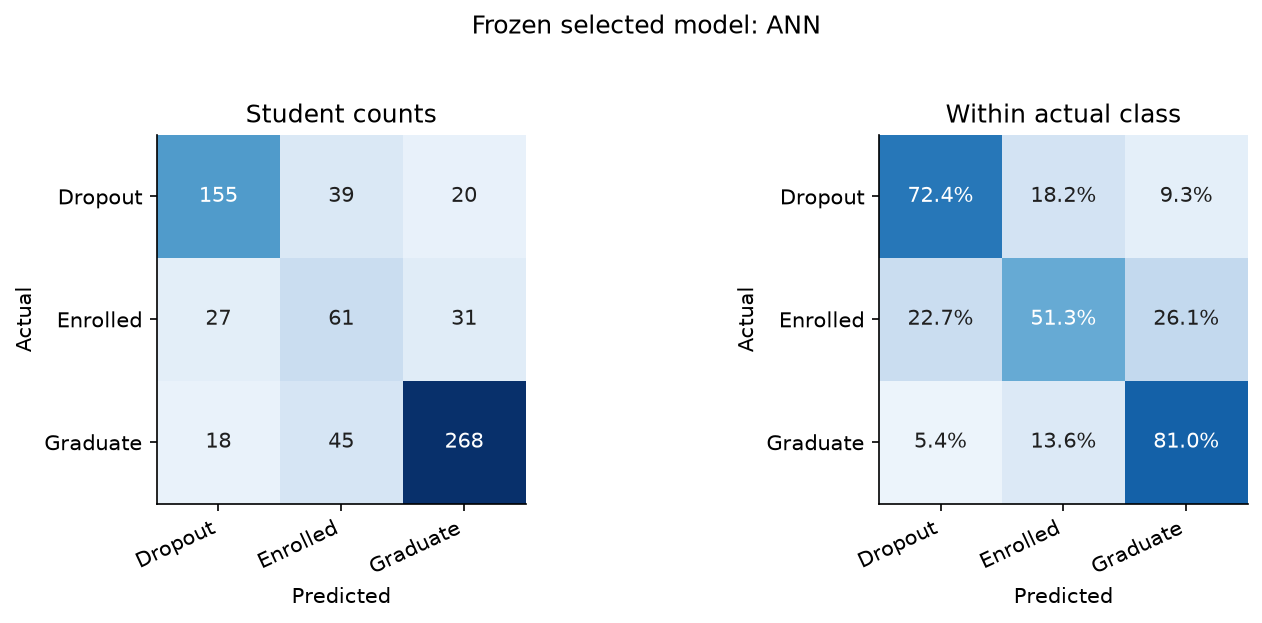

,group,value,n,dropout_n,macro_f1,accuracy,balanced_accuracy,dropout_precision,dropout_recall
0,age,21-25,134,45,0.6879,0.7090,0.6962,0.7692,0.6667
1,age,<=20,368,73,0.6573,0.7364,0.6582,0.6479,0.6301
2,age,>25,162,96,0.6165,0.7284,0.6229,0.8778,0.8229
3,gender_code,0,420,98,0.6730,0.7476,0.6756,0.7590,0.6429
4,gender_code,1,244,116,0.6532,0.6967,0.6533,0.7863,0.7931
5,scholarship,0,501,201,0.6668,0.6986,0.6744,0.7903,0.7313
6,scholarship,1,163,13,0.6325,0.8221,0.6265,0.5714,0.6154
7,zero_passed_sem1,False,563,130,0.6400,0.7069,0.6397,0.6822,0.5615
8,zero_passed_sem1,True,101,84,0.5225,0.8515,0.4828,0.8817,0.9762


,row_id,actual,predicted,confidence,incorrect
0,1106,Dropout,Graduate,0.905813,True
1,479,Enrolled,Graduate,0.871594,True
2,3733,Dropout,Graduate,0.871509,True
3,1686,Graduate,Dropout,0.862842,True
4,369,Dropout,Graduate,0.821729,True
5,3891,Enrolled,Graduate,0.819101,True
6,1141,Enrolled,Graduate,0.810494,True
7,2000,Dropout,Enrolled,0.806136,True
8,4413,Enrolled,Dropout,0.798337,True
9,1570,Enrolled,Graduate,0.795577,True


,feature,validation_importance_mean,validation_importance_std
0,Curricular units 1st sem (pass_rate),0.1237,0.0084
1,Curricular units 1st sem (approved),0.0830,0.0080
2,Curricular units 1st sem (grade),0.0514,0.0064
3,Course,0.0430,0.0102
4,Curricular units 1st sem (evaluations_per_unit),0.0381,0.0067
5,Curricular units 1st sem (evaluations),0.0341,0.0069
6,Age at enrollment,0.0311,0.0099
7,Application mode,0.0257,0.0041
8,Curricular units 1st sem (enrolled),0.0231,0.0093
9,Father's occupation,0.0231,0.0058


In [15]:
display(Image(filename=str(ROOT / 'artifacts/figures/selected_confusion_matrix.png')))
display(pd.read_csv(ROOT / 'artifacts/tables/test_error_groups.csv').round(4))
display(pd.read_csv(ROOT / 'artifacts/tables/selected_test_errors.csv').head(10))
display(pd.read_csv(ROOT / 'artifacts/tables/validation_permutation_importance.csv').head(10).round(4))

Permutation importance вычислена на validation. Коррелированные исходные и производные признаки затрудняют индивидуальную интерпретацию; это не причинные эффекты. Один вуз, исторические наборы студентов, отсутствие индивидуальных дат отчисления и неполная доступность временных статусов ограничивают переносимость результата. Предсказания не являются основанием для автоматического отчисления.

ANN ошиблась на 180 из 664 test-наблюдений. Для Enrolled верно распознаны 61/119 (51.3%); этот класс неоднороден и пересекается с другими исходами. Из 214 случаев Dropout 20 названы Graduate, а 39 — Enrolled. Разбор таких ошибок полезнее одной accuracy.

## 12. Выводы и оставшаяся работа

ANN выбрана по validation Macro F1=0.6625; test Macro F1=0.6785, против 0.2218 у Dummy. Сравнение ANN, PCA, кластеров и профилей признаков основано на сохранённых экспериментах. Численная часть не заменяет обзор литературы, 2–3-страничный proposal, итоговый отчёт, презентацию и техническую подготовку каждого участника.

## Начальные источники

- [UCI dataset, DOI 10.24432/C5MC89](https://doi.org/10.24432/C5MC89).
- Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). [Predicting Student Dropout and Academic Success](https://doi.org/10.3390/data7110146). *Data, 7*(11), 146.
- [scikit-learn: preprocessing](https://scikit-learn.org/stable/modules/preprocessing.html).
- [scikit-learn: cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html).
- [scikit-learn: MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html).
- [scikit-learn: clustering](https://scikit-learn.org/stable/modules/clustering.html).
- [scikit-learn: PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

Это начальные технические ссылки, а не завершённая библиография из 10+ преимущественно научных источников.